In [1]:
import torch

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.11.0+cu130
GPU disponible : True
GPU : Tesla T4


In [2]:
from pathlib import Path

for path in Path("/kaggle/input").iterdir():
    print(path.name)
    for item in list(path.iterdir())[:10]:
        print("  ", item.name)

datasets
   nouhebenkhelil


In [3]:
from pathlib import Path

root = Path("/kaggle/input")

for category in ["bottle", "hazelnut", "leather"]:
    matches = list(root.rglob(f"{category}/train/good"))
    print(category, ":", [
        len(list(p.glob("*.png"))) for p in matches
    ])

bottle : [209]
hazelnut : [391]
leather : [245]


In [4]:
import sys
import torch
from pathlib import Path

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("GPU :", torch.cuda.get_device_name(0))

assert (3, 11) <= sys.version_info[:2] < (3, 14)
assert torch.cuda.is_available()

matches = list(Path("/kaggle/input").rglob("bottle/train/good"))
assert len(matches) == 1, matches

DATA_ROOT = matches[0].parents[2]

for category in ["bottle", "hazelnut", "leather"]:
    assert (DATA_ROOT / category / "train/good").is_dir()

print("Dataset :", DATA_ROOT)
print("Environnement OK")

Python : 3.13.16
PyTorch : 2.11.0+cu130
GPU : Tesla T4
Dataset : /kaggle/input/datasets/nouhebenkhelil/resilientinspect-mvtec3
Environnement OK


In [5]:
import subprocess
import sys
import torch
from pathlib import Path

REPO = Path("/kaggle/working/resilientinspect-ai")

if not REPO.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/nouhabenkhelil/resilientinspect-ai.git",
        str(REPO)
    ], check=True)
else:
    subprocess.run(
        ["git", "-C", str(REPO), "pull", "--ff-only"],
        check=True
    )

torch_before = torch.__version__

# Protéger la version CUDA existante
constraints = Path("/kaggle/working/torch_constraints.txt")
constraints.write_text(f"torch=={torch_before}\n")

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "-e", f"{REPO}[train,dev]",
    "-c", str(constraints)
], check=True)

from importlib.metadata import version

assert version("torch") == torch_before
print("Installation réussie")
print("PyTorch CUDA conservé :", version("torch"))

Cloning into '/kaggle/working/resilientinspect-ai'...


Obtaining file:///kaggle/working/resilientinspect-ai
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 14.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 12.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 7.2 MB/s  0:00:00
  Building editable for resilientinspect-ai (pyproject.toml): started
  Buildi

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.10.8 which is incompatible.


Installation réussie
PyTorch CUDA conservé : 2.11.0+cu130


In [6]:
import hashlib

MANIFEST = REPO / "data/manifests/manifest.csv"

subprocess.run([
    sys.executable, "-m",
    "resilientinspect.data.prepare",
    "--root", str(DATA_ROOT),
    "--output-dir", str(MANIFEST.parent),
    "--report", "/kaggle/working/kaggle_preparation.json"
], cwd=REPO, check=True)

sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()

EXPECTED = "13f55c7cf7c87a3e3739e24920bb0d85cc96a39a00e30d277ddfaa1832b84522"

print("SHA256 :", sha)
assert sha == EXPECTED, "Manifestes différents du PC local"
print("Splits validés !")

{
  "counts": {
    "bottle": {
      "train": 167,
      "val": 42,
      "test": 83,
      "test_good": 20,
      "test_anomalous": 63
    },
    "hazelnut": {
      "train": 312,
      "val": 79,
      "test": 110,
      "test_good": 40,
      "test_anomalous": 70
    },
    "leather": {
      "train": 196,
      "val": 49,
      "test": 124,
      "test_good": 32,
      "test_anomalous": 92
    }
  },
  "totals": {
    "train": 675,
    "val": 170,
    "test": 317
  },
  "manifest_sha256": {
    "manifest.csv": "13f55c7cf7c87a3e3739e24920bb0d85cc96a39a00e30d277ddfaa1832b84522",
    "train.csv": "781b1143fee9eab14f871f4f6335a94f9832c8bb0f13efbb8c40f54d3eadc5d4",
    "val.csv": "08f10f23fa04a531188684a46ae2578c9337e8c81f6c3c20aaf1b3c20b963092",
    "test.csv": "10b4d50e66d9c98cfd53a55b304be4fe150ad4e1eaf7e7a99c1c019d793d30ac"
  }
}
SHA256 : 13f55c7cf7c87a3e3739e24920bb0d85cc96a39a00e30d277ddfaa1832b84522
Splits validés !


In [7]:
subprocess.run([
    sys.executable, "-m", "pytest",
    "tests/test_models.py", "-q"
], cwd=REPO, check=True)

.......................                                                  [100%]
23 passed in 6.22s


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', 'tests/test_models.py', '-q'], returncode=0)

In [8]:
subprocess.run([
    sys.executable, "-m",
    "resilientinspect.training.train_ae",
    "--config", str(REPO / "configs/train_ae_b0.yaml"),
    "--root", str(DATA_ROOT),
    "--manifest", str(MANIFEST),
    "--category", "bottle",
    "--device", "cuda",
    "--output-dir", "/kaggle/working/b0_runs",
    "--smoke"
], cwd=REPO, check=True)

2026/11/08 14:00:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/08 14:00:46 INFO mlflow.store.db.utils: Updating database tables


{"category": "bottle", "scope": "smoke", "epoch": 1, "train_loss": 0.2950209379196167, "val_loss": 0.33240267634391785, "train_images": 4, "val_images": 4, "train_batches": 2, "val_batches": 2}
{
  "run_id": "5999f03c92ef4b169e64bf31d984f6d4",
  "run_dir": "/kaggle/working/b0_runs/bottle/smoke_5999f03c92ef4b169e64bf31d984f6d4",
  "category": "bottle",
  "scope": "smoke",
  "best_epoch": 1,
  "best_val_loss": 0.33240267634391785
}


CompletedProcess(args=['/usr/bin/python3', '-m', 'resilientinspect.training.train_ae', '--config', '/kaggle/working/resilientinspect-ai/configs/train_ae_b0.yaml', '--root', '/kaggle/input/datasets/nouhebenkhelil/resilientinspect-mvtec3', '--manifest', '/kaggle/working/resilientinspect-ai/data/manifests/manifest.csv', '--category', 'bottle', '--device', 'cuda', '--output-dir', '/kaggle/working/b0_runs', '--smoke'], returncode=0)

In [9]:

import subprocess
import sys

command = [
    sys.executable, "-m",
    "resilientinspect.training.train_ae",
    "--config", str(REPO / "configs/train_ae_b0.yaml"),
    "--root", str(DATA_ROOT),
    "--manifest", str(MANIFEST),
    "--category", "bottle",
    "--device", "cuda",
    "--output-dir", "/kaggle/working/b0_runs"
]

subprocess.run(command, cwd=REPO, check=True)

print("Entraînement complet B0 terminé.")


{"category": "bottle", "scope": "full", "epoch": 1, "train_loss": 0.1867855191230774, "val_loss": 0.27163808118729366, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3}
{"category": "bottle", "scope": "full", "epoch": 2, "train_loss": 0.07269026608970351, "val_loss": 0.12491526632081895, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3}
{"category": "bottle", "scope": "full", "epoch": 3, "train_loss": 0.040494646408600725, "val_loss": 0.08099963090249471, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3}
{"category": "bottle", "scope": "full", "epoch": 4, "train_loss": 0.032263238127984685, "val_loss": 0.05108759020056043, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3}
{"category": "bottle", "scope": "full", "epoch": 5, "train_loss": 0.028646519251480075, "val_loss": 0.033777767703646704, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3}
{"categ

Statut : completed
Époques exécutées : 20
Meilleure époque : 19
Meilleure validation L1 : 0.018117047136738187
Checkpoint : /kaggle/working/b0_runs/bottle/full_7b8b71d28bc44868840ca50f4b16f4a1/best.pt


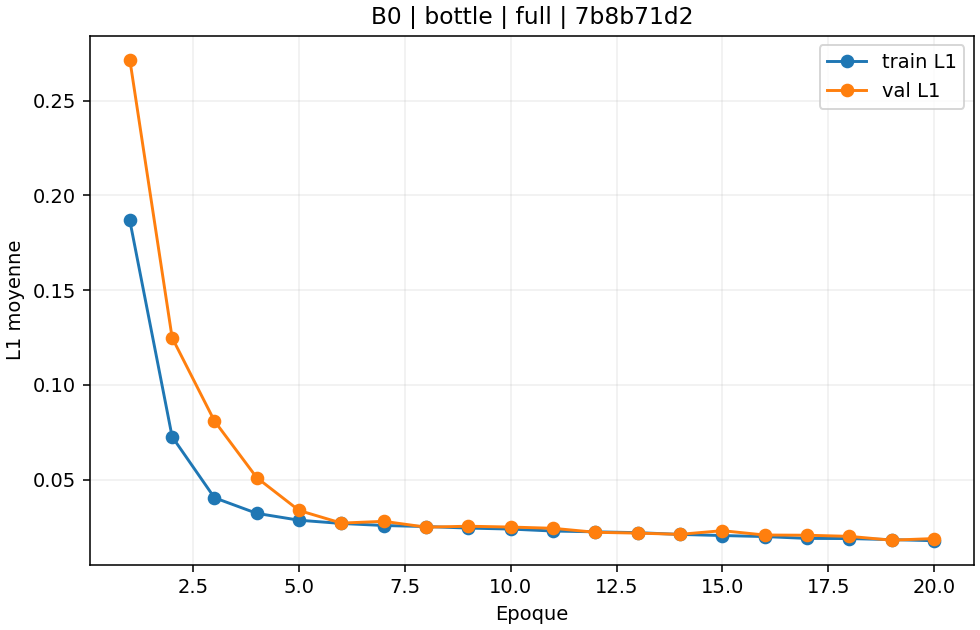

In [10]:

import json
from pathlib import Path
from IPython.display import display, Image

runs = sorted(
    Path("/kaggle/working/b0_runs/bottle").glob("full_*/summary.json"),
    key=lambda p: p.stat().st_mtime
)

assert runs, "Aucun entraînement complet trouvé"

run_dir = runs[-1].parent
summary = json.loads(runs[-1].read_text())

assert summary["scope"] == "full"
assert summary["test_used"] is False
assert (run_dir / "best.pt").is_file()

print("Statut :", summary["status"])
print("Époques exécutées :", summary["epochs_completed"])
print("Meilleure époque :", summary["best_epoch"])
print("Meilleure validation L1 :", summary["best_val_loss"])
print("Checkpoint :", run_dir / "best.pt")

display(Image(filename=str(run_dir / "loss_curves.png")))


In [11]:
import shutil

archive = shutil.make_archive(
    "/kaggle/working/b0_runs_backup",
    "zip",
    root_dir="/kaggle/working",
    base_dir="b0_runs"
)

print("Archive créée :", archive)

Archive créée : /kaggle/working/b0_runs_backup.zip


In [12]:
from pathlib import Path
from IPython.display import FileLink, display

archive = Path("/kaggle/working/b0_runs_backup.zip")

assert archive.is_file(), "Archive introuvable"

print("Taille :", round(archive.stat().st_size / 1024**2, 2), "Mo")
display(FileLink(str(archive)))

Taille : 8.58 Mo


/kaggle/working/b0_runs_backup.zip

In [13]:

import sys
import subprocess
import site
import sysconfig
import importlib
from pathlib import Path

import torch

REPO = Path("/kaggle/working/resilientinspect-ai")

# Récupérer le dépôt si nécessaire
if not (REPO / "pyproject.toml").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/nouhabenkhelil/resilientinspect-ai.git",
        str(REPO)
    ], check=True)

commit = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
    text=True
).strip()

print("Commit GitHub :", commit)

# Conserver exactement le PyTorch CUDA existant
torch_version = torch.__version__
constraints = Path("/kaggle/working/torch_constraints.txt")
constraints.write_text(f"torch=={torch_version}\n")

# Installer le package et les dépendances d'entraînement
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", f"{REPO}[train]",
    "-c", str(constraints)
], check=True)

# Activer les chemins créés par l'installation éditable
site.addsitedir(sysconfig.get_paths()["purelib"])
importlib.invalidate_caches()

import resilientinspect
from resilientinspect.models.autoencoder import ConvAutoencoder
from resilientinspect.data.dataset import MVTecDataset

assert torch.__version__ == torch_version
assert torch.cuda.is_available()

print("Package chargé avec succès !")
print("PyTorch :", torch.__version__)
print("GPU :", torch.cuda.get_device_name(0))


Commit GitHub : f1403b3
Package chargé avec succès !
PyTorch : 2.11.0+cu130
GPU : Tesla T4


In [14]:

import hashlib

matches = list(
    Path("/kaggle/input").rglob("bottle/train/good")
)
assert len(matches) == 1, matches

DATA_ROOT = matches[0].parents[2]
MANIFEST = REPO / "data/manifests/manifest.csv"

if not MANIFEST.exists():
    subprocess.run([
        sys.executable, "-m",
        "resilientinspect.data.prepare",
        "--root", str(DATA_ROOT),
        "--output-dir", str(MANIFEST.parent),
        "--report", "/kaggle/working/kaggle_preparation.json"
    ], cwd=REPO, check=True)

EXPECTED_SHA = (
    "13f55c7cf7c87a3e3739e24920bb0d85cc96"
    "a39a00e30d277ddfaa1832b84522"
)

actual_sha = hashlib.sha256(
    MANIFEST.read_bytes()
).hexdigest()

assert actual_sha == EXPECTED_SHA, "Splits différents !"

print("Dataset :", DATA_ROOT)
print("Manifestes identiques au PC local.")
print("Préparation OK")


Dataset : /kaggle/input/datasets/nouhebenkhelil/resilientinspect-mvtec3
Manifestes identiques au PC local.
Préparation OK


In [15]:

from zipfile import ZipFile

RUN_ROOT = Path("/kaggle/working/b0_runs")

def find_bottle():
    return list(
        (RUN_ROOT / "bottle").glob("full_*/best.pt")
    )

if not find_bottle():
    archives = [
        Path("/kaggle/working/b0_runs_backup.zip"),
        *Path("/kaggle/input").rglob("b0_runs_backup.zip")
    ]
    archives = [p for p in archives if p.is_file()]

    if archives:
        with ZipFile(archives[0]) as z:
            members = [
                name for name in z.namelist()
                if name.startswith("b0_runs/bottle/")
            ]
            assert members
            assert all(
                ".." not in Path(name).parts
                for name in members
            )
            z.extractall("/kaggle/working", members)

checkpoints = find_bottle()

assert checkpoints, (
    "Checkpoint Bottle absent. Il faut ajouter "
    "b0_runs_backup.zip aux fichiers Kaggle."
)

checkpoint_path = max(
    checkpoints, key=lambda p: p.stat().st_mtime
)

print("B0 Bottle retrouvé !")
print(checkpoint_path)


B0 Bottle retrouvé !
/kaggle/working/b0_runs/bottle/full_7b8b71d28bc44868840ca50f4b16f4a1/best.pt


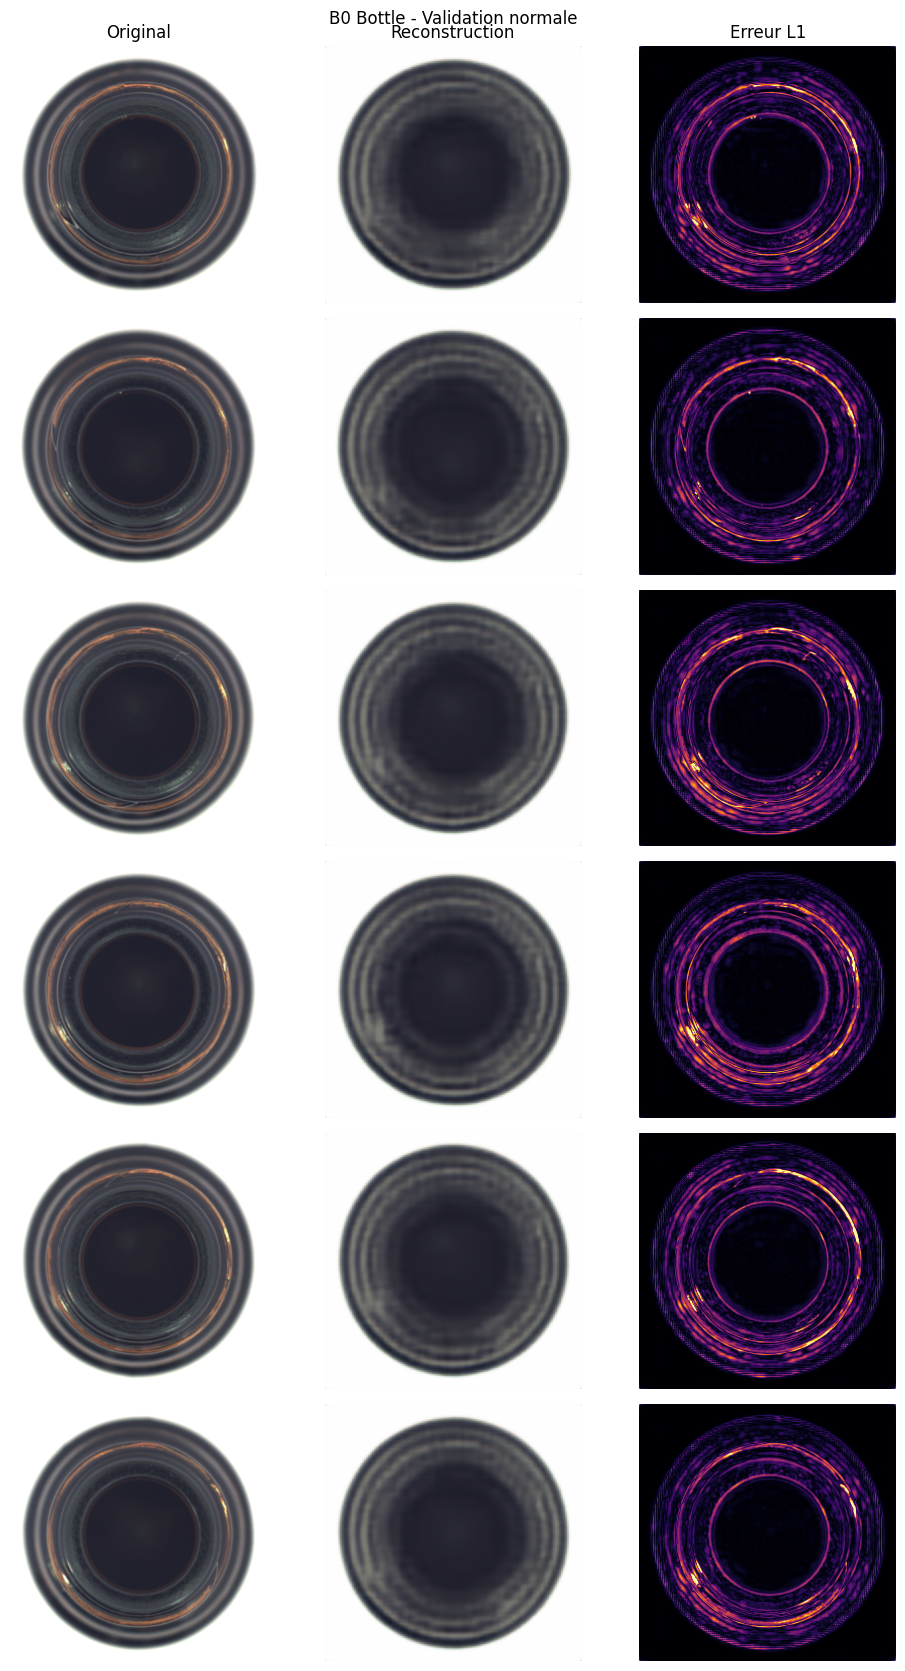

Figure enregistrée : /kaggle/working/b0_bottle_reconstructions.png


In [16]:

import numpy as np
import matplotlib.pyplot as plt
import torch

from IPython.display import display, Image as DisplayImage

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["category"] == "bottle"
assert checkpoint["scope"] == "full"

model = ConvAutoencoder()
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

val_dataset = MVTecDataset(
    MANIFEST,
    DATA_ROOT,
    split="val",
    categories=["bottle"]
)

indices = np.linspace(
    0, len(val_dataset) - 1, 6, dtype=int
)

fig, axes = plt.subplots(6, 3, figsize=(10, 17))

with torch.inference_mode():
    for i, idx in enumerate(indices):
        sample = val_dataset[int(idx)]
        original = sample["image"]

        reconstructed = model(
            original.unsqueeze(0)
        )[0]

        error = torch.abs(
            original - reconstructed
        ).mean(dim=0)

        axes[i, 0].imshow(
            original.permute(1, 2, 0).numpy()
        )
        axes[i, 1].imshow(
            reconstructed.permute(1, 2, 0).numpy()
        )
        axes[i, 2].imshow(
            error.numpy(),
            cmap="inferno",
            vmin=0,
            vmax=0.2
        )

        for ax in axes[i]:
            ax.axis("off")

for j, title in enumerate([
    "Original", "Reconstruction", "Erreur L1"
]):
    axes[0, j].set_title(title)

plt.suptitle("B0 Bottle - Validation normale")
plt.tight_layout()

figure_path = Path(
    "/kaggle/working/b0_bottle_reconstructions.png"
)

plt.savefig(figure_path, dpi=150)
plt.show()

print("Figure enregistrée :", figure_path)


In [17]:

import json

assert torch.cuda.is_available(), "GPU requis"

for category in ["hazelnut", "leather"]:

    print(f"\n====== B0 {category.upper()} ======")

    existing = list(
        (RUN_ROOT / category).glob("full_*/summary.json")
    )

    completed = any(
        json.loads(p.read_text()).get("status")
        == "completed"
        and (p.parent / "best.pt").is_file()
        for p in existing
    )

    if completed:
        print("Entraînement déjà terminé : ignoré.")
        continue

    command = [
        sys.executable, "-m",
        "resilientinspect.training.train_ae",
        "--config",
        str(REPO / "configs/train_ae_b0.yaml"),
        "--root", str(DATA_ROOT),
        "--manifest", str(MANIFEST),
        "--category", category,
        "--device", "cuda",
        "--output-dir", str(RUN_ROOT)
    ]

    subprocess.run(
        command,
        cwd=REPO,
        check=True
    )

    print(f"B0 {category} terminé.")

print("\nEntraînements demandés exécutés.")



====== B0 HAZELNUT ======
{"category": "hazelnut", "scope": "full", "epoch": 1, "train_loss": 0.20772849653775877, "val_loss": 0.2055116541023496, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5}
{"category": "hazelnut", "scope": "full", "epoch": 2, "train_loss": 0.043310024321843416, "val_loss": 0.04753765954247004, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5}
{"category": "hazelnut", "scope": "full", "epoch": 3, "train_loss": 0.020204975245854795, "val_loss": 0.030079219608178623, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5}
{"category": "hazelnut", "scope": "full", "epoch": 4, "train_loss": 0.016876767317836102, "val_loss": 0.021002925342962712, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5}
{"category": "hazelnut", "scope": "full", "epoch": 5, "train_loss": 0.015282922304975681, "val_loss": 0.01668254017264028, "train_images": 312, "val_images": 79, "train_


=== BOTTLE ===
Époques : 20
Meilleure époque : 19
Validation L1 : 0.018117047136738187
Checkpoint : /kaggle/working/b0_runs/bottle/full_7b8b71d28bc44868840ca50f4b16f4a1/best.pt


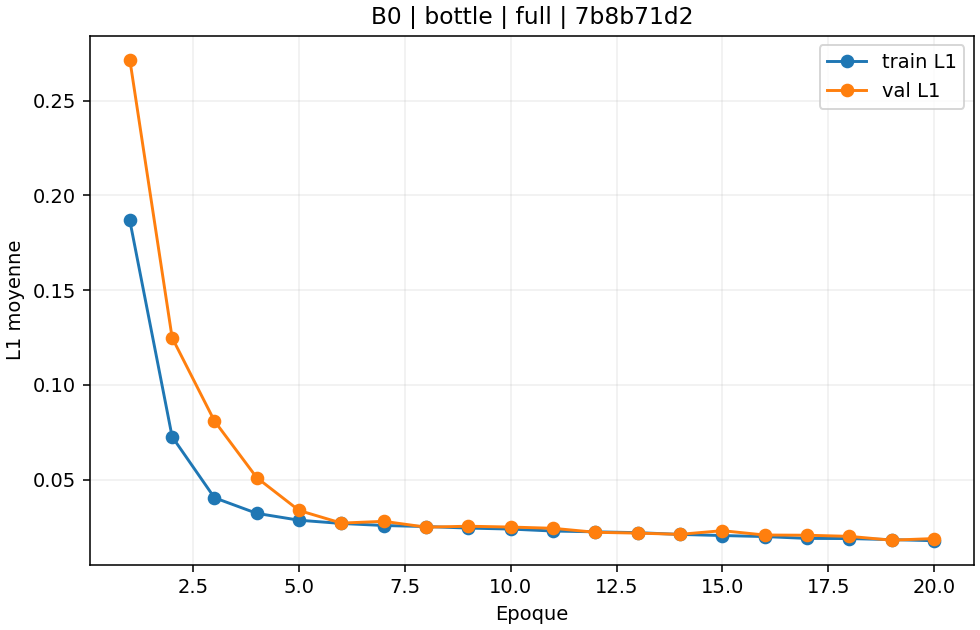


=== HAZELNUT ===
Époques : 20
Meilleure époque : 18
Validation L1 : 0.010424418327740477
Checkpoint : /kaggle/working/b0_runs/hazelnut/full_7ad19992bae44fcb9a04b5e7e15eccaf/best.pt


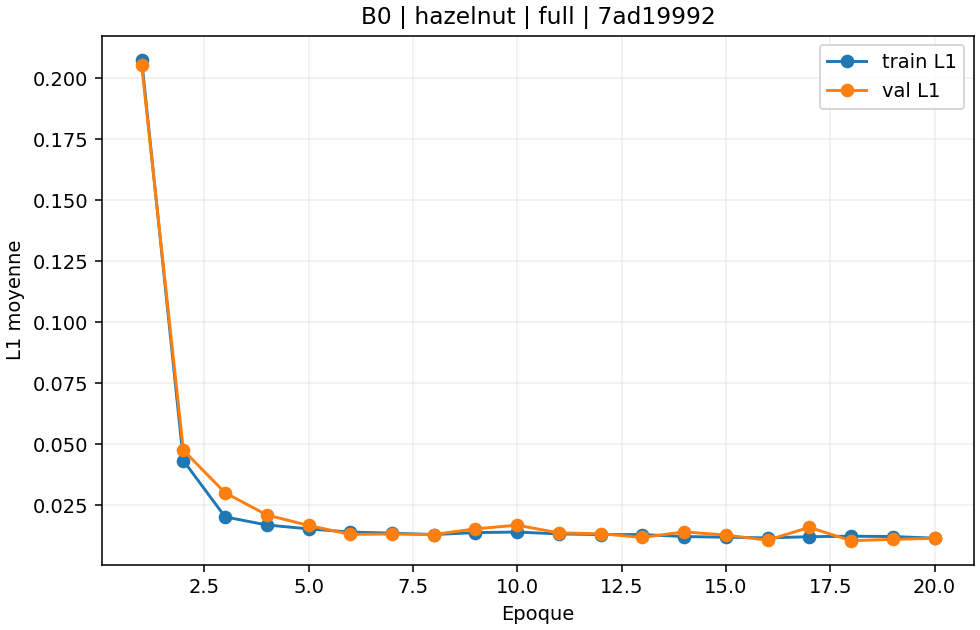


=== LEATHER ===
Époques : 19
Meilleure époque : 14
Validation L1 : 0.018880066214775552
Checkpoint : /kaggle/working/b0_runs/leather/full_15ee92b51d3e4ff99632422619e64c00/best.pt


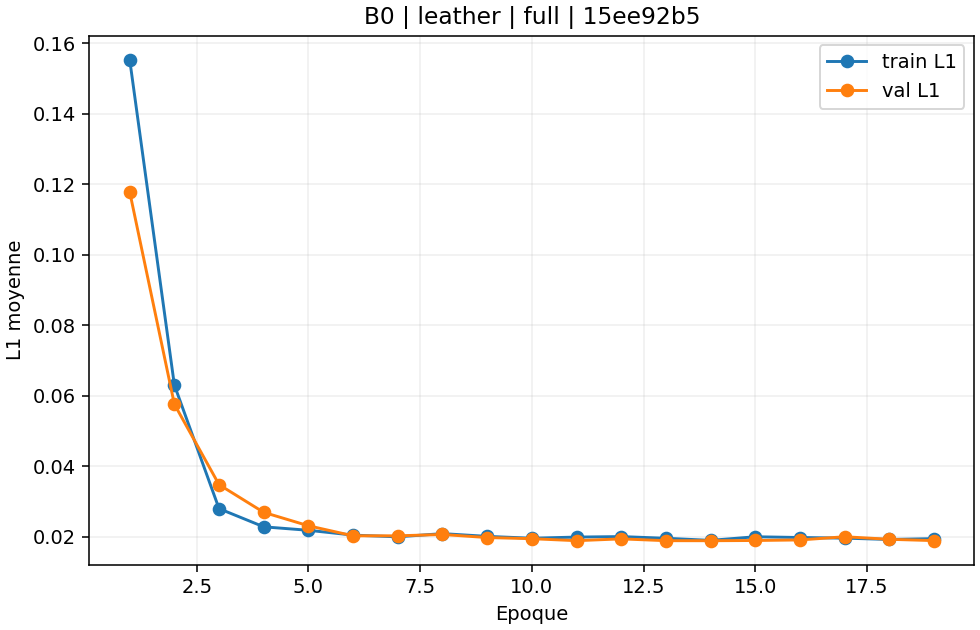


Modèles complets disponibles : 3 / 3


In [18]:

import json
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

results = {}

for category in ["bottle", "hazelnut", "leather"]:

    summaries = list(
        (RUN_ROOT / category).glob("full_*/summary.json")
    )

    if not summaries:
        print(category, ": aucun résultat complet")
        continue

    summary_file = max(
        summaries, key=lambda p: p.stat().st_mtime
    )

    summary = json.loads(summary_file.read_text())
    directory = summary_file.parent

    assert summary["status"] == "completed"
    assert summary["test_used"] is False
    assert (directory / "best.pt").is_file()

    results[category] = summary

    print(f"\n=== {category.upper()} ===")
    print("Époques :", summary["epochs_completed"])
    print("Meilleure époque :", summary["best_epoch"])
    print("Validation L1 :", summary["best_val_loss"])
    print("Checkpoint :", directory / "best.pt")

    curve = directory / "loss_curves.png"
    if curve.is_file():
        display(DisplayImage(filename=str(curve)))

print("\nModèles complets disponibles :", len(results), "/ 3")


In [19]:

import shutil
from pathlib import Path
from IPython.display import FileLink, display

assert len(results) == 3, (
    "Les trois modèles B0 doivent être terminés."
)

archive = shutil.make_archive(
    "/kaggle/working/B0_ResilientInspect_3categories",
    "zip",
    root_dir="/kaggle/working",
    base_dir="b0_runs"
)

archive = Path(archive)

assert archive.is_file()

print("Archive créée :", archive)
print(
    "Taille :",
    round(archive.stat().st_size / 1024**2, 2),
    "Mo"
)

display(FileLink(str(archive)))


Archive créée : /kaggle/working/B0_ResilientInspect_3categories.zip
Taille : 17.19 Mo


/kaggle/working/B0_ResilientInspect_3categories.zip